# Orchestration: batch reconstruction

Runs several projects independently from one config file: `run_batch()` validates every project up front (advisory only -- it never skips a project because of what validation found), then attempts every one, so a single project's failure never stops the rest. See [`ORCHESTRATION.md`](../ORCHESTRATION.md)'s "Batch runs" section, and [`05_orchestration.ipynb`](./05_orchestration.ipynb) for the single-project case this builds on.

In [1]:
import sys
from pathlib import Path

here = Path.cwd()
project_root = next(p for p in [here, *here.parents] if (p / "data_import").is_dir())
sys.path.insert(0, str(project_root))

print("Using project root:", project_root)

Using project root: D:\GitHub\Universial-Reconstructions - Copy\.claude\worktrees\code-package-review-13feda


## 1. Generate sample data

Same generator as the single-project notebook: three HDF5 projects (200/300/400 projections) and two TIFF projects (200/300), a realistic ~1.5%-of-width center-of-rotation offset, and no injected tilt (see [`05_orchestration.ipynb`](./05_orchestration.ipynb) for why those choices).

In [2]:
from tests.fixtures.realistic_phantom import generate, write_hdf5, write_tiff

OUT = Path("generated/orchestration")
OUT.mkdir(parents=True, exist_ok=True)

SHAPE = (16, 64, 64)

for n_angles in (200, 300, 400):
    phantom = generate(shape=SHAPE, n_angles=n_angles, cor_deviation=1.0, tilt_deg=0.0,
                        n_scratches=0, n_defective_pixels=0, inhomogeneity_strength=0.0,
                        noise_level=0.0, seed=n_angles)
    write_hdf5(phantom, OUT / f"scan_{n_angles}.h5")

for n_angles in (200, 300):
    phantom = generate(shape=SHAPE, n_angles=n_angles, cor_deviation=1.0, tilt_deg=0.0,
                        n_scratches=0, n_defective_pixels=0, inhomogeneity_strength=0.0,
                        noise_level=0.0, seed=n_angles)
    write_tiff(phantom, OUT / f"scan_{n_angles}_tiff")

print("Generated:", sorted(p.name for p in OUT.iterdir()))

Generated: ['scan_200.h5', 'scan_200_tiff', 'scan_200_tiff_reconstructed', 'scan_300.h5', 'scan_300_reconstructed.h5', 'scan_300_reconstructed_1.h5', 'scan_300_tiff', 'scan_400.h5']


## 2. A batch config file: 3 reconstructions in one file

`example_batch_projects.ini`, sitting alongside this notebook. `[DEFAULT:stage]` supplies values every project inherits unless its own section overrides that key -- here, all three projects share the same reconstruction backend and output dtype, and only `[import]`/`[export]` differ per project.

In [3]:
print(Path("example_batch_projects.ini").read_text())

# Batch orchestration config: 3 reconstructions in one file. See
# doc/ORCHESTRATION.md's "Batch grammar" section. Used by
# doc/demo/06_batch_orchestration.ipynb, against the sample data that
# notebook generates at generated/orchestration/scan_{200,300,400}.h5.
#
# Sections are [project_id:stage]. [DEFAULT:stage] supplies a value
# every project inherits unless its own section overrides that key --
# scoped per stage, not configparser's built-in [DEFAULT], since "path"
# means something different in [import] than in [export].

[DEFAULT:reconstruction]
backend = algotom_fbp

[DEFAULT:postprocess]
dtype = float32

[scan_200:import]
path = generated/orchestration/scan_200.h5
format = hdf5

[scan_200:export]
format = hdf5
path = generated/orchestration/scan_200_reconstructed.h5

[scan_300:import]
path = generated/orchestration/scan_300.h5
format = hdf5

[scan_300:export]
format = hdf5
path = generated/orchestration/scan_300_reconstructed.h5

[scan_400:import]
path = generated/orchestrati

## 3. Loading it

Auto-detected as a batch file (section names contain `:`); `load_config()` returns `{project_id: ProjectConfig}` instead of one config.

In [4]:
from orchestration import load_config

configs = load_config("example_batch_projects.ini")
print("projects:", list(configs))
for project_id, config in configs.items():
    print(f"  {project_id}: path={config.path}  backend={config.reconstruction_backend}")

projects: ['scan_200', 'scan_300', 'scan_400']
  scan_200: path=generated/orchestration/scan_200.h5  backend=algotom_fbp
  scan_300: path=generated/orchestration/scan_300.h5  backend=algotom_fbp
  scan_400: path=generated/orchestration/scan_400.h5  backend=algotom_fbp


## 4. Validating before running

`validate_config()` dry-runs import, completion, preprocessing, and calibration for one config -- cheap relative to reconstruction, and enough to catch a real config/data problem before committing an entire overnight batch to it.

In [5]:
from orchestration import validate_config

for project_id, config in configs.items():
    problems = validate_config(config)
    status = "OK" if not problems else f"PROBLEMS: {problems}"
    print(f"{project_id}: {status}")

C:\Users\a6237\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\algotom\prep\calculation.py:203: UserWarning: Global minimum is out of the searching range. Please reduce the starting value !!!
  warnings.warn(msg)


scan_200: OK


scan_300: OK


scan_400: OK


## 5. Running the batch

`run_batch()` runs every project, independently. Validation above was advisory only -- it doesn't skip anything here, it just told us in advance what to expect.

In [6]:
from orchestration import run_batch

report = run_batch(list(configs.values()))

print("succeeded:", [r.project_id for r in report.succeeded])
print("failed:   ", [r.project_id for r in report.failed])

C:\Users\a6237\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\algotom\rec\reconstruction.py:422: UserWarning: !!!No Nvidia GPU found! Run with CPU instead!!!
  warnings.warn("!!!No Nvidia GPU found! Run with CPU instead!!!")


C:\Users\a6237\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\algotom\prep\calculation.py:203: UserWarning: Global minimum is out of the searching range. Please reduce the starting value !!!
  warnings.warn(msg)


succeeded: ['scan_200', 'scan_300', 'scan_400']
failed:    []


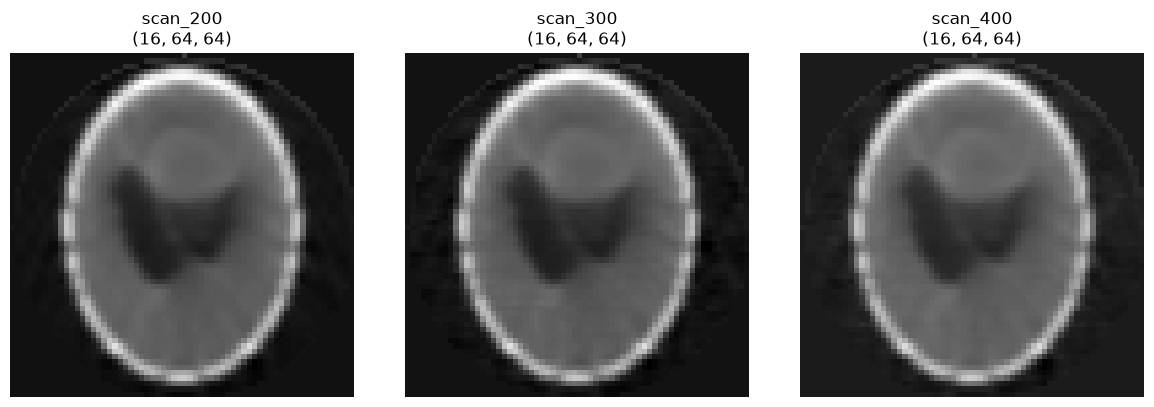

In [7]:
import h5py
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(report.succeeded), figsize=(4 * len(report.succeeded), 4))
for ax, result in zip(axes, report.succeeded):
    with h5py.File(result.volume_path, "r") as f:
        volume = f["/volume"][()]
    ax.imshow(volume[volume.shape[0] // 2], cmap="gray")
    ax.set_title(f"{result.project_id}\n{volume.shape}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Resilience: one bad project doesn't stop the rest

Adding a fourth project that's missing a required field (no `geometry_type`, and nothing in its config answers it) -- exactly the "discover this before you leave for the night" case from `ORCHESTRATION.md`. It gets a real attempt like every other project; it just fails at the `complete()` stage, and the other three are unaffected.

In [8]:
from tests.fixtures.generate_hypothetical_synchrotron import generate as generate_hypothetical
from orchestration import ProjectConfig

broken_path = OUT / "scan_broken.h5"
generate_hypothetical(broken_path, shape=(4, 16, 16), n_angles=10)  # geometry_type never set

broken_config = ProjectConfig(
    path=str(broken_path), format="hdf5", project_id="scan_broken",
    export_format="hdf5", export_path=str(OUT / "scan_broken_reconstructed.h5"),
)

batch_with_a_bad_project = list(configs.values()) + [broken_config]
report2 = run_batch(batch_with_a_bad_project)

print("succeeded:", [r.project_id for r in report2.succeeded])
print("failed:   ", [r.project_id for r in report2.failed])
print("validation_problems:", report2.validation_problems)

C:\Users\a6237\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\algotom\prep\calculation.py:203: UserWarning: Global minimum is out of the searching range. Please reduce the starting value !!!
  warnings.warn(msg)


C:\Users\a6237\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\algotom\rec\reconstruction.py:422: UserWarning: !!!No Nvidia GPU found! Run with CPU instead!!!
  warnings.warn("!!!No Nvidia GPU found! Run with CPU instead!!!")


succeeded: ['scan_200', 'scan_300', 'scan_400']
failed:    ['scan_broken']
validation_problems: {'scan_broken': ["[complete] missing required fields: ['geometry_type']"]}


## 7. Retrying just what failed

`PipelineResult.config` is the config that produced it, so fixing and re-running only the broken project doesn't mean re-running the whole batch.

In [9]:
import dataclasses

fixed_configs = [
    dataclasses.replace(r.config, completion_answers={"geometry_type": "parallel"})
    for r in report2.failed
]
retry_report = run_batch(fixed_configs)
print("succeeded on retry:", [r.project_id for r in retry_report.succeeded])

succeeded on retry: ['scan_broken']


C:\Users\a6237\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\algotom\rec\reconstruction.py:433: UserWarning: !!!Applying logarithm is enabled but there are values <= 0.0 in the data!!!
  warnings.warn("!!!Applying logarithm is enabled but "


## 8. TIFF projects, the same way

`run_batch()` doesn't know or care what format each project is -- a small batch of the two TIFF projects works identically, `storage_mode="disk"` and all.

In [10]:
tiff_configs = [
    ProjectConfig(
        path=str(OUT / f"scan_{n}_tiff"), format="tiff", storage_mode="disk", project_id=f"scan_{n}_tiff",
        export_format="tiff", export_path=str(OUT / f"scan_{n}_tiff_reconstructed"),
    )
    for n in (200, 300)
]

tiff_report = run_batch(tiff_configs)
print("succeeded:", [r.project_id for r in tiff_report.succeeded])
print("failed:   ", [r.project_id for r in tiff_report.failed])

succeeded: ['scan_200_tiff', 'scan_300_tiff']
failed:    []


## Recap

```
[project_id:stage] / [DEFAULT:stage] INI file  --load_config()-->  {project_id: ProjectConfig}
                                                          |
                                        validate_config() each  -->  advisory report
                                                          |
                                        run_batch()  -->  every project attempted independently
                                                          |
                                        BatchReport: .succeeded, .failed, .validation_problems
                                                          |
                       PipelineResult.config lets you retry only what failed
```

See [`ORCHESTRATION.md`](../ORCHESTRATION.md) for the full reference, and [`05_orchestration.ipynb`](./05_orchestration.ipynb) for the single-project, step-by-step view of what each `PipelineRun` inside this batch is actually doing.